In [1]:
!pip install torchvision adabelief-pytorch==0.2.0 lion-pytorch -q


In [2]:
pip install kaggle torchvision

Note: you may need to restart the kernel to use updated packages.


In [3]:
# =============================================================
# INSTALLATION, IMPORTS, AND GLOBAL CONFIGURATION
# =============================================================

# Install all required packages including specialized optimizers and monitoring tools
!pip install scikit-learn thop pynvml matplotlib seaborn tqdm torchinfo -q

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
import numpy as np
import matplotlib.pyplot as plt
import time
import random
import os
import seaborn as sns
import thop
import pynvml
import torch.nn.functional as F
import warnings
from tqdm import tqdm
from collections import Counter, deque
from torch.utils.data import DataLoader, Dataset, random_split
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.preprocessing import label_binarize

# Suppress non-critical warnings for clean log reporting
warnings.filterwarnings("ignore")

# Establish seed
SEED = 1337
def set_seed(seed=1337):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

print("✓ All libraries installed.")
print(f"PyTorch Version: {torch.__version__}")



/usr/local/lib/python3.10/site-packages/torch/cuda/__init__.py:68: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


✓ All libraries installed.
PyTorch Version: 2.10.0


In [4]:
import os
import shutil
from getpass import getpass

kaggle_path = input("Upload the kaggle.json: ")
dest_path = os.path.expanduser('~/.kaggle/kaggle.json')
os.makedirs(os.path.dirname(dest_path), exist_ok=True)
shutil.copy(kaggle_path, dest_path)
os.chmod(dest_path, 0o600)
print("✓ Kaggle configured")


✓ Kaggle configured


In [5]:
# =============================================================
# GLOBAL CONFIGURATION - RAABIN WBC (100 EPOCHS)
# =============================================================
import torch
import numpy as np
import random

# For reproducibility
SEED = 1337
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Constants
NUM_CLASSES = 5      # Basophil, Eosinophil, Lymphocyte, Monocyte, Neutrophil
NUM_EPOCHS  = 80
BATCH_SIZE  = 64
IMG_SIZE    = 128    # 128×128 px
device      = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Hyperparameters used in all experiments (no per-optimizer tuning).
# SGD: He et al. (2016) | Adam/Adamax: Kingma & Ba (2015) | AdamW: Loshchilov & Hutter (2019)
# RAdam: Liu et al. (2020) | AMSGrad: Reddi et al. (2018) | AdaBelief: Zhuang et al. (2020)
# Lion: Chen et al. (2023) | RMSprop: Tieleman & Hinton (2012)
HYPERPARAMS = {
    'SGD':       {'lr': 0.01,  'momentum': 0.9, 'weight_decay': 0},
    'RMSprop':   {'lr': 1e-3, 'alpha': 0.99, 'eps': 1e-8},
    'Adam':      {'lr': 1e-3, 'betas': (0.9, 0.999), 'eps': 1e-8},
    'AdamW':     {'lr': 1e-3, 'betas': (0.9, 0.999), 'eps': 1e-8, 'weight_decay': 0.01},
    'RAdam':     {'lr': 1e-3, 'betas': (0.9, 0.999), 'eps': 1e-8},
    'AMSGrad':   {'lr': 1e-3, 'betas': (0.9, 0.999), 'eps': 1e-8, 'weight_decay': 0, 'amsgrad': True},
    'Adamax':    {'lr': 2e-3, 'betas': (0.9, 0.999), 'eps': 1e-8, 'weight_decay': 0},
    'AdaBelief': {'lr': 1e-3, 'betas': (0.9, 0.999), 'eps': 1e-8, 'weight_decay': 0,
                  'weight_decouple': False, 'rectify': False},
    'Lion':      {'lr': 1e-4, 'betas': (0.9, 0.99), 'weight_decay': 0.1},
    'AdaHarmon': {'lr': 1e-3, 'betas': (0.9, 0.999, 0.9), 'eps': (1e-8, 1e-6),
                  'lambda_s': 1.0, 'soft_decay': 0.5, 'tau': 0.1, 'amsgrad': False},
}

OPTIMIZERS_TO_RUN = ["Adam", "AdamW", "RAdam", "AdaHarmon", "RMSprop", "SGD", "AdaBelief", "Lion", "AMSGrad", "Adamax"]

print(f"✓ Global config set.")
print(f"  Dataset    : Raabin-WBC")
print(f"  Classes    : {NUM_CLASSES}")
print(f"  Image size : {IMG_SIZE}×{IMG_SIZE}")
print(f"  Batch size : {BATCH_SIZE}")
print(f"  Epochs     : {NUM_EPOCHS}")
print(f"  Device     : {device}")


✓ Global config set.
  Dataset    : Raabin-WBC
  Classes    : 5
  Image size : 128×128
  Batch size : 64
  Epochs     : 80
  Device     : cuda


In [6]:
# =============================================================
# DATASET CONFIGURATION - RAABIN WBC
# =============================================================

import os
import shutil
import glob

dataset_path    = '/content/raabin_wbc'
master_data_dir = os.path.join(dataset_path, 'full_dataset')
categories      = ['Basophil', 'Eosinophil', 'Lymphocyte', 'Monocyte', 'Neutrophil']
VALID_EXTENSIONS = ('.jpg', '.jpeg', '.png')

# ─── GUARD: checks if full_dataset already has images ───
sample_check = os.path.join(master_data_dir, 'Neutrophil')
already_done = (
    os.path.exists(sample_check) and
    len([f for f in os.listdir(sample_check) if f.lower().endswith(VALID_EXTENSIONS)]) > 0
)

if already_done:
    print('full_dataset already exists — skipping download & consolidation.')
else:
    print('full_dataset not found — downloading from Kaggle...')
    os.makedirs(dataset_path, exist_ok=True)

    # ─── DOWNLOAD ───
    os.system(f'kaggle datasets download -d raabindata/raabin-wbc -p {dataset_path} --unzip')
    print('✓ Download complete.')

    # ─── CONSOLIDATION ───
    os.makedirs(master_data_dir, exist_ok=True)

    source_dirs = [
        os.path.join(dataset_path, 'Train/Train'),
        os.path.join(dataset_path, 'TestA/TestA'),
        os.path.join(dataset_path, 'TestB/Test-B'),
    ]

    print("\nConsolidating images into 'full_dataset'...")
    for category in categories:
        target_dir = os.path.join(master_data_dir, category)
        os.makedirs(target_dir, exist_ok=True)
        for s_dir in source_dirs:
            source_category_path = os.path.join(s_dir, category)
            if os.path.exists(source_category_path):
                files_found = [
                    f for f in glob.glob(os.path.join(source_category_path, '*'))
                    if f.lower().endswith(VALID_EXTENSIONS)
                ]
                for f in files_found:
                    shutil.copy2(f, target_dir)
            else:
                print(f' Not found: {source_category_path}')

    print('Consolidation complete.')

# ─── FINAL VERIFICATION ───
print(f'\nFinal population per category:')
grand_total = 0
for category in categories:
    count = len([
        f for f in os.listdir(os.path.join(master_data_dir, category))
        if f.lower().endswith(VALID_EXTENSIONS)
    ])
    print(f'  \U0001f4c2 {category:<15}: {count} images')
    grand_total += count
print(f"\n  {'TOTAL':<15}: {grand_total} images")



full_dataset already exists — skipping download & consolidation.

Final population per category:
  📂 Basophil       : 100 images
  📂 Eosinophil     : 100 images
  📂 Lymphocyte     : 100 images
  📂 Monocyte       : 100 images
  📂 Neutrophil     : 100 images

  TOTAL          : 500 images


✓ Total population (N): 500

Class distribution matrix:
  Class                N       %
  ----------------------------------------
  Basophil           100   20.0%  ██████████
  Eosinophil         100   20.0%  ██████████
  Lymphocyte         100   20.0%  ██████████
  Monocyte           100   20.0%  ██████████
  Neutrophil         100   20.0%  ██████████


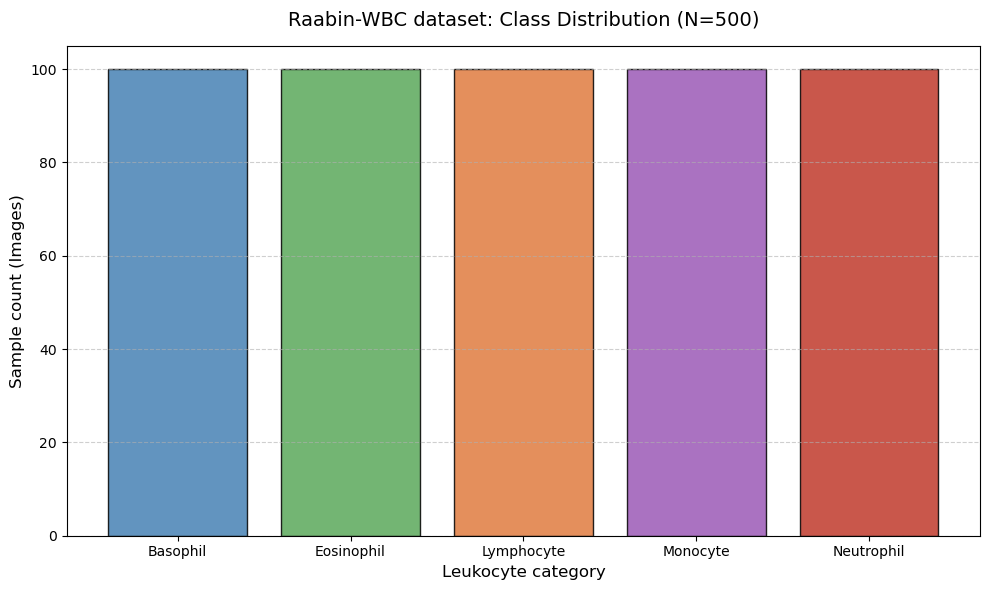


 EDA completed.
NOTE: Dataset is highly imbalanced.


In [7]:
import os
import matplotlib.pyplot as plt

base_dir = '/content/raabin_wbc/full_dataset'
VALID_EXTENSIONS = ('.jpg', '.jpeg', '.png')

class_map_name = {
    'Basophil':   'Basophil',
    'Eosinophil': 'Eosinophil',
    'Lymphocyte': 'Lymphocyte',
    'Monocyte':   'Monocyte',
    'Neutrophil': 'Neutrophil'
}

data_summary = []
for category in sorted(os.listdir(base_dir)):
    path = os.path.join(base_dir, category)
    if os.path.isdir(path):
        n = len([f for f in os.listdir(path) if f.lower().endswith(VALID_EXTENSIONS)])
        data_summary.append((category, n))

total_n = sum(count for _, count in data_summary)
print(f'✓ Total population (N): {total_n}')
print(f'\nClass distribution matrix:')
print(f"  {'Class':<15} {'N':>6} {'%':>7}")
print(f"  {'-'*40}")
for code, n in data_summary:
    pct = (n / total_n) * 100
    bar_visual = '█' * int(pct / 2)
    print(f'  {code:<15} {n:>6} {pct:>6.1f}%  {bar_visual}')

plt.figure(figsize=(10, 6))
codes  = [item[0] for item in data_summary]
counts = [item[1] for item in data_summary]
colors = ['#4682B4', '#5BA85A', '#E07B3F', '#9B59B6', '#C0392B']
plt.bar(codes, counts, color=colors, edgecolor='black', alpha=0.85)
plt.title(f'Raabin-WBC dataset: Class Distribution (N={total_n:,})', fontsize=14, pad=15)
plt.xlabel('Leukocyte category', fontsize=12)
plt.ylabel('Sample count (Images)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print('\n EDA completed.')
print('NOTE: Dataset is highly imbalanced.')



  CLASS WEIGHTING STRATEGY (for CrossEntropyLoss)
  Formula: total_N / (n_classes × class_N)
  Total N  : 500
  N classes: 5

  Class                 N     Weight
  -----------------------------------
  Basophil            100     1.0000
  Eosinophil          100     1.0000
  Lymphocyte          100     1.0000
  Monocyte            100     1.0000
  Neutrophil          100     1.0000

 WeightedRandomSampler ready.
  Samples per epoch : 1,500
  Basophil: ~3.0x by epoch (before ~11x)


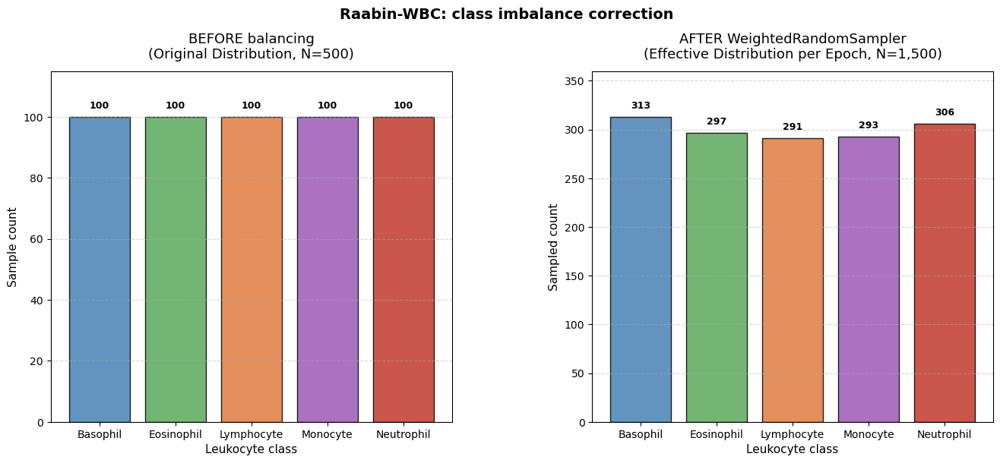


 Balancing strategy configured.
  → class_weights  : used in CrossEntropyLoss(weight=...)
  → sample_weights : used in WeightedRandomSampler
  → No images duplicated or deleted.


In [8]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from collections import Counter

base_dir = '/content/raabin_wbc/full_dataset'
VALID_EXTENSIONS = ('.jpg', '.jpeg', '.png')

categories = sorted(os.listdir(base_dir))
class_counts = {}
for category in categories:
    path = os.path.join(base_dir, category)
    n = len([f for f in os.listdir(path) if f.lower().endswith(VALID_EXTENSIONS)])
    class_counts[category] = n

total_n   = sum(class_counts.values())
n_classes = len(categories)

# ─── 1. CLASS WEIGHTS FOR LOSS FUNCTION ───
class_weights = {
    cls: total_n / (n_classes * count)
    for cls, count in class_counts.items()
}

print("=" * 55)
print("  CLASS WEIGHTING STRATEGY (for CrossEntropyLoss)")
print("=" * 55)
print(f"  Formula: total_N / (n_classes × class_N)")
print(f"  Total N  : {total_n:,}")
print(f"  N classes: {n_classes}")
print(f"\n  {'Class':<15} {'N':>7} {'Weight':>10}")
print(f"  {'-'*35}")
for cls in categories:
    print(f"  {cls:<15} {class_counts[cls]:>7,} {class_weights[cls]:>10.4f}")

# ─── 2. WEIGHTED RANDOM SAMPLER ───
all_labels = []
for idx, cls in enumerate(categories):
    all_labels.extend([idx] * class_counts[cls])

sample_weights = [
    class_weights[categories[label]] for label in all_labels
]
# Basophil (301) will be seen ~3x per epoch
num_samples = int(min(class_counts.values())) * n_classes * 3
# = 301 * 5 * 3 = 4,515

print(f"\n WeightedRandomSampler ready.")
print(f"  Samples per epoch : {num_samples:,}")
print(f"  Basophil: ~{num_samples // n_classes / min(class_counts.values()):.1f}x by epoch (before ~11x)")

# ─── 3. DISTRIBUTION ───
np.random.seed(1337)
probs          = np.array(sample_weights) / np.array(sample_weights).sum()
sampled_epoch  = np.random.choice(len(all_labels), size=num_samples, replace=True, p=probs)
sampled_counts = Counter([categories[all_labels[i]] for i in sampled_epoch])

# ─── 4. VISUALIZATION: BEFORE vs AFTER ───
fig = plt.figure(figsize=(16, 6))
gs  = gridspec.GridSpec(1, 2, wspace=0.35)
colors = ['#4682B4', '#5BA85A', '#E07B3F', '#9B59B6', '#C0392B']

ax1 = fig.add_subplot(gs[0])
vals_before = [class_counts[c] for c in categories]
bars1 = ax1.bar(categories, vals_before, color=colors, edgecolor='black', alpha=0.85)
ax1.set_title(f"BEFORE balancing\n(Original Distribution, N={total_n:,})", fontsize=13, pad=12)
ax1.set_xlabel("Leukocyte class", fontsize=11)
ax1.set_ylabel("Sample count", fontsize=11)
ax1.grid(axis='y', linestyle='--', alpha=0.5)
ax1.set_ylim(0, max(vals_before) * 1.15)
for bar, val in zip(bars1, vals_before):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(vals_before)*0.02,
             f'{val:,}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax2 = fig.add_subplot(gs[1])
vals_after = [sampled_counts[c] for c in categories]
bars2 = ax2.bar(categories, vals_after, color=colors, edgecolor='black', alpha=0.85)
ax2.set_title(f"AFTER WeightedRandomSampler\n(Effective Distribution per Epoch, N={num_samples:,})", fontsize=13, pad=12)
ax2.set_xlabel("Leukocyte class", fontsize=11)
ax2.set_ylabel("Sampled count", fontsize=11)
ax2.grid(axis='y', linestyle='--', alpha=0.5)
ax2.set_ylim(0, max(vals_after) * 1.15)
for bar, val in zip(bars2, vals_after):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(vals_after)*0.02,
             f'{val:,}', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.suptitle("Raabin-WBC: class imbalance correction",
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n Balancing strategy configured.")
print("  → class_weights  : used in CrossEntropyLoss(weight=...)")
print("  → sample_weights : used in WeightedRandomSampler")
print("  → No images duplicated or deleted.")


In [9]:
# =============================================================
# MODEL ARCHITECTURE DEFINITION (RESNET18)
# =============================================================
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights
import warnings

import torch.nn as nn
from torchvision.models import resnet18

class ResNet18(nn.Module):
    """
    ResNet18 architecture initialized with random weights (no pre-training).
    """
    def __init__(self, num_classes=5):
        super(ResNet18, self).__init__()
        # Initializing without pre-trained weights
        self.model = resnet18(weights=None)

        # Adjusting the final fully connected layer
        in_features = self.model.fc.in_features
        self.model.fc = nn.Sequential(
            nn.Dropout(p=0.5), # Dropout for scratch training stability
            nn.Linear(in_features, num_classes)
        )
        
    def forward(self, x):
        return self.model(x)


In [10]:
# =============================================================
# PROPOSED OPTIMIZER
# =============================================================
import torch
from torch.optim import Optimizer


class AdaHarmon(Optimizer):
    r"""
    AdaHarmon: Adaptive Harmonic Optimizer

    Algorithm:
    ----------
    Let g_t be the gradient at step t.

    1. Sign consistency tracker:
       s_t = β_s · s_{t-1} + (1 - β_s) · sign(g_t)

    2. Adaptive momentum:
       β₁^(t) = β₁ · (1 + λ|s_t|) / (1 + λ)
       μ_t    = μ_{t-1} · β₁^(t)           ← exact accumulated product

    3. First moment (gradient EMA):
       m_t = β₁^(t) · m_{t-1} + (1 - β₁^(t)) · g_t
       m̂_t = m_t / (1 - μ_t)               ← exact bias correction

    4. Second moment (L2 norm):
       v_t = β₂ · v_{t-1} + (1 - β₂) · g_t²
       v̂_t = v_t / (1 - β₂^t)

    5. L∞ norm with soft decay:
       δ_t = 1 + soft_decay · 𝟙[|g_t| < τ · u_{t-1}]
       u_t = max(β₂^{δ_t} · u_{t-1}, |g_t|)

    6. Hybrid denominator (harmonic mean of L2 and L∞):
       h̃_t = 2·√v̂_t · u_t / (√v̂_t + u_t + ε₁)

    7. Parameter update:
       θ_t = θ_{t-1} - α · m̂_t / (h̃_t + ε₂)

    Arguments:
    ----------
    params      : model parameters
    lr          : learning rate α (default: 1e-3)
    betas       : (β₁, β₂, β_s) EMA coefficients (default: 0.9, 0.999, 0.9)
    eps         : (ε₁, ε₂) inner and outer epsilons (default: 1e-8, 1e-6)
    lambda_s    : λ scale for adaptive momentum (default: 1.0)
    soft_decay  : extra decay when gradient < threshold (default: 0.5)
    tau         : relative threshold for u_t decay (default: 0.1)
    amsgrad     : use AMSGrad variant for second moment (default: False)
    """

    def __init__(
        self,
        params,
        lr: float = 1e-3,
        betas: tuple = (0.9, 0.999, 0.9),
        eps: tuple = (1e-8, 1e-6),
        lambda_s: float = 1.0,
        soft_decay: float = 0.5,
        tau: float = 0.1,
        amsgrad: bool = False,
    ):
        if lr < 0.0:
            raise ValueError(f"Invalid lr: {lr}")
        if not (0.0 <= betas[0] < 1.0):
            raise ValueError(f"Invalid β₁: {betas[0]}")
        if not (0.0 <= betas[1] < 1.0):
            raise ValueError(f"Invalid β₂: {betas[1]}")
        if not (0.0 <= betas[2] < 1.0):
            raise ValueError(f"Invalid β_s: {betas[2]}")
        if eps[0] <= 0 or eps[1] <= 0:
            raise ValueError(f"eps must be positive: {eps}")

        defaults = dict(
            lr=lr,
            betas=betas,
            eps=eps,
            lambda_s=lambda_s,
            soft_decay=soft_decay,
            tau=tau,
            amsgrad=amsgrad,
        )
        super(AdaHarmon, self).__init__(params, defaults)

    def __setstate__(self, state):
        super(AdaHarmon, self).__setstate__(state)
        for group in self.param_groups:
            group.setdefault("amsgrad", False)

    @torch.no_grad()
    def step(self, closure=None):
        """Performs a single optimization step."""
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            beta1, beta2, beta_s = group["betas"]
            eps1, eps2 = group["eps"]
            lr = group["lr"]
            lambda_s = group["lambda_s"]
            soft_decay = group["soft_decay"]
            tau = group["tau"]
            amsgrad = group["amsgrad"]

            for p in group["params"]:
                if p.grad is None:
                    continue

                grad = p.grad
                if grad.is_sparse:
                    raise RuntimeError(
                        "AdaHarmon does not support sparse gradients."
                    )

                state = self.state[p]

                # ── State initialization ───────────────────────────────────
                if len(state) == 0:
                    state["step"] = 0
                    state["m"] = torch.zeros_like(p)   # first moment
                    state["v"] = torch.zeros_like(p)   # second moment (L2)
                    state["u"] = torch.zeros_like(p)   # L∞ norm
                    state["s"] = torch.zeros_like(p)   # sign consistency tracker
                    state["mu"] = torch.ones_like(p)   # accumulated product μ_t
                    if amsgrad:
                        state["v_max"] = torch.zeros_like(p)

                state["step"] += 1
                t = state["step"]
                m, v, u, s, mu = (
                    state["m"], state["v"], state["u"],
                    state["s"], state["mu"]
                )

                # ── Step 1: Sign consistency tracker ──────────────────────
                # s_t = β_s · s_{t-1} + (1 - β_s) · sign(g_t)
                s.mul_(beta_s).add_(torch.sign(grad), alpha=(1.0 - beta_s))

                # ── Step 2: Adaptive momentum per parameter ────────────────
                # β₁^(t) = β₁ · (1 + λ|s_t|) / (1 + λ)
                beta1_t = beta1 * (1.0 + lambda_s * s.abs()) / (1.0 + lambda_s)
                beta1_t.clamp_(0.0, 1.0 - 1e-9)

                # μ_t = μ_{t-1} · β₁^(t)  (exact accumulated product)
                mu.mul_(beta1_t)

                # ── Step 3: First moment with exact bias correction ────────
                # m_t = β₁^(t) · m_{t-1} + (1 - β₁^(t)) · g_t
                m.mul_(beta1_t).addcmul_(
                    (1.0 - beta1_t), grad
                )
                # m̂_t = m_t / (1 - μ_t)
                bias_correction_m = 1.0 - mu
                bias_correction_m.clamp_(min=1e-12)  # avoid div/0 at step 1
                m_hat = m / bias_correction_m

                # ── Step 4: Second moment (L2 norm) ───────────────────────
                # v_t = β₂ · v_{t-1} + (1 - β₂) · g_t²
                v.mul_(beta2).addcmul_(grad, grad, value=(1.0 - beta2))

                if amsgrad:
                    v_max = state["v_max"]
                    torch.maximum(v_max, v, out=v_max)
                    v_eff = v_max
                else:
                    v_eff = v

                # v̂_t = v_t / (1 - β₂^t)
                bias_correction_v = 1.0 - beta2 ** t
                v_hat = v_eff / bias_correction_v

                # ── Step 5: L∞ norm with soft decay ───────────────────────
                # δ_t: extra decay when |g_t| < τ · u_{t-1}
                # Prevents u_t from freezing at historical peaks
                grad_abs = grad.abs()
                plateau_mask = (grad_abs < tau * u).float()
                # β₂^δ_t where δ_t = 1 + soft_decay · 𝟙[plateau]
                beta2_eff = beta2 ** (1.0 + soft_decay * plateau_mask)
                # u_t = max(β₂^{δ_t} · u_{t-1}, |g_t|)
                torch.maximum(beta2_eff * u, grad_abs, out=u)

                # ── Step 6: Hybrid denominator (harmonic mean) ─────────────
                # h̃_t = 2·√v̂_t · u_t / (√v̂_t + u_t + ε₁)
                sqrt_v_hat = v_hat.sqrt()
                numerator = 2.0 * sqrt_v_hat * u
                denominator_inner = sqrt_v_hat + u + eps1
                h_tilde = numerator / denominator_inner

                # ── Step 7: Parameter update ──────────────────────────────
                # θ_t = θ_{t-1} - α · m̂_t / (h̃_t + ε₂)
                p.addcdiv_(m_hat, h_tilde + eps2, value=-lr)

        return loss

In [11]:
# =============================================================
# OPTIMIZER COMPLEXITY AND EFFICIENCY ANALYSIS
# =============================================================
import pynvml
import warnings

class OptimizerComplexity:
    """
    Analyzes the computational overhead and energy efficiency of the optimizers.
    Metrics based on Floating Point Operations (FLOPs) per parameter.
    """
    def __init__(self, optimizer_name, num_params):
        self.optimizer_name = optimizer_name
        self.num_params     = num_params
        self.ops_per_param  = self._estimate_flops_per_param()

    def _estimate_flops_per_param(self):
        """
        FLOPs per parameter for the optimizer step alone.
        Convention follows Sun et al. (2020), AdaBelief, Appendix A.
        Values match Table 5 of the manuscript.
        """
        if self.optimizer_name == "SGD":
            # v = beta*v + g; theta = theta - lr*v
            return 4
        elif self.optimizer_name == "RMSprop":
            # v = beta*v + (1-beta)*g^2; theta = theta - lr*g/(sqrt(v)+eps)
            return 9
        elif self.optimizer_name == "Adam":
            # m, v updates + bias-corrected parameter step
            return 14
        elif self.optimizer_name == "AdamW":
            # Adam + decoupled weight decay (theta = theta - lr*wd*theta)
            return 16
        elif self.optimizer_name == "RAdam":
            # Adam + variance rectification term
            return 15
        elif self.optimizer_name == "AdaHarmon":
            # sign EMA + adaptive momentum + soft-decay L_inf + harmonic mean
            return 37
        elif self.optimizer_name == "AdaBelief":
            # m update, s update with (g - m)^2, bias corrections, update step
            return 16
        elif self.optimizer_name == "Lion":
            # c_t update, sign step, decoupled wd, m update
            return 7
        elif self.optimizer_name == "AMSGrad":
            # Adam + max(v_max, v) tracking
            return 15
        elif self.optimizer_name == "Adamax":
            # m update + infinity norm update + update step
            return 11
        else:
            warnings.warn(f"Optimizer '{self.optimizer_name}' not standardized. Returning 0.")
            return 0

    def get_flops_per_param(self):
        return self.ops_per_param

    def get_total_flops(self):
        """Total theoretical FLOPs for one full update of the model."""
        return self.ops_per_param * self.num_params

    def get_estimated_energy_joules(self, total_time_s):
        """
        Estimates energy consumption in Joules using NVML power metrics.
        Fallback to 250W average TDP for standard research GPUs.
        """
        try:
            pynvml.nvmlInit()
            handle = pynvml.nvmlDeviceGetHandleByIndex(0)
            power_mw = pynvml.nvmlDeviceGetPowerUsage(handle)
            pynvml.nvmlShutdown()
            return (power_mw / 1000.0) * total_time_s
        except Exception:
            return 250.0 * total_time_s

In [12]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize


def count_parameters(model):
    """Calculates the total number of trainable parameters in the model."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def train_and_evaluate_model(model, optimizer_name, hparams,
                              train_loader, train_eval_loader,
                              val_loader, test_loader,
                              train_dataset, val_dataset, test_dataset,
                              NUM_EPOCHS, NUM_CLASSES, device):
    model.to(device)

            # ── OPTIMIZER INITIALIZATION ──────────────────────────────────────────────
    if optimizer_name == "Adam":
        optimizer = optim.Adam(
            model.parameters(),
            lr=hparams['lr'],
            betas=hparams.get('betas', (0.9, 0.999)),
            eps=hparams.get('eps', 1e-8)
        )
    elif optimizer_name == "AdamW":
        optimizer = optim.AdamW(
            model.parameters(),
            lr=hparams['lr'],
            betas=hparams.get('betas', (0.9, 0.999)),
            eps=hparams.get('eps', 1e-8),
            weight_decay=hparams.get('weight_decay', 0.01)
        )
    elif optimizer_name == "RAdam":
        optimizer = optim.RAdam(
            model.parameters(),
            lr=hparams['lr'],
            betas=hparams.get('betas', (0.9, 0.999)),
            eps=hparams.get('eps', 1e-8)
        )
    elif optimizer_name == "AdaHarmon":
        optimizer = AdaHarmon(
            model.parameters(),
            lr=hparams['lr'],
            betas=hparams.get('betas', (0.9, 0.999, 0.9)),
            eps=hparams.get('eps', (1e-8, 1e-6)),
            lambda_s=hparams.get('lambda_s', 1.0),
            soft_decay=hparams.get('soft_decay', 0.5),
            tau=hparams.get('tau', 0.1),
            amsgrad=hparams.get('amsgrad', False)
        )
    elif optimizer_name == "RMSprop":
        optimizer = optim.RMSprop(
            model.parameters(),
            lr=hparams['lr'],
            alpha=hparams.get('alpha', 0.99),
            eps=hparams.get('eps', 1e-8)
        )
    elif optimizer_name == "SGD":
        optimizer = optim.SGD(
            model.parameters(),
            lr=hparams['lr'],
            momentum=hparams.get('momentum', 0.9),
            weight_decay=hparams.get('weight_decay', 0)
        )
    elif optimizer_name == "AdaBelief":
        from adabelief_pytorch import AdaBelief
        optimizer = AdaBelief(
            model.parameters(),
            lr=hparams['lr'],
            betas=hparams.get('betas', (0.9, 0.999)),
            eps=hparams.get('eps', 1e-8),
            weight_decay=hparams.get('weight_decay', 0),
            weight_decouple=hparams.get('weight_decouple', False),
            rectify=hparams.get('rectify', False),
            print_change_log=False
        )
    elif optimizer_name == "Lion":
        from lion_pytorch import Lion
        optimizer = Lion(
            model.parameters(),
            lr=hparams['lr'],
            betas=hparams.get('betas', (0.9, 0.99)),
            weight_decay=hparams.get('weight_decay', 0.1)
        )
    elif optimizer_name == "AMSGrad":
        optimizer = optim.Adam(
            model.parameters(),
            lr=hparams['lr'],
            betas=hparams.get('betas', (0.9, 0.999)),
            eps=hparams.get('eps', 1e-8),
            weight_decay=hparams.get('weight_decay', 0),
            amsgrad=True
        )
    elif optimizer_name == "Adamax":
        optimizer = optim.Adamax(
            model.parameters(),
            lr=hparams['lr'],
            betas=hparams.get('betas', (0.9, 0.999)),
            eps=hparams.get('eps', 1e-8),
            weight_decay=hparams.get('weight_decay', 0)
        )
    else:
        raise ValueError(f"Unknown optimizer: {optimizer_name}")

    criterion = nn.CrossEntropyLoss(weight=class_weights_t)

    # ── HISTORIAL ─────────────────────────────────────────────────────────────
    history = {
        'train_loss': [], 'val_loss': [],
        'train_acc':  [], 'val_acc':  [],
        'val_auc':    [], 'epoch_times': []
    }

    best_val_acc = 0.0
    best_epoch   = 0
    start_time   = time.time()

    
    for epoch in range(NUM_EPOCHS):
        epoch_start = time.time()

        # ── Training phase ────────────────────────────────────────────────────
        model.train()
        for inputs, batch_labels in train_loader:
            inputs, batch_labels = inputs.to(device), batch_labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, batch_labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

        # ── Evaluation phase ──────────────────────────────────────────────────
        model.eval()

        metrics = {
            'trn': {'loss': 0.0, 'corr': 0, 'tot': 0},
            'val': {'loss': 0.0, 'corr': 0, 'tot': 0, 'scores': [], 'labels': []}
        }

        with torch.no_grad():
            for inputs, batch_labels in train_eval_loader:
                inputs, batch_labels = inputs.to(device), batch_labels.to(device)
                outputs = model(inputs)
                loss    = criterion(outputs, batch_labels)
                metrics['trn']['loss'] += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs.data, 1)
                metrics['trn']['tot']  += batch_labels.size(0)
                metrics['trn']['corr'] += (predicted == batch_labels).sum().item()

            for inputs, batch_labels in val_loader:
                inputs, batch_labels = inputs.to(device), batch_labels.to(device)
                outputs = model(inputs)
                loss    = criterion(outputs, batch_labels)
                metrics['val']['loss'] += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs.data, 1)
                metrics['val']['tot']  += batch_labels.size(0)
                metrics['val']['corr'] += (predicted == batch_labels).sum().item()
                metrics['val']['labels'].extend(batch_labels.cpu().numpy())
                metrics['val']['scores'].append(F.softmax(outputs, dim=1).cpu().numpy())

        epoch_trn_loss = metrics['trn']['loss'] / len(train_dataset)
        epoch_trn_acc  = metrics['trn']['corr'] / metrics['trn']['tot']
        epoch_val_loss = metrics['val']['loss'] / len(val_dataset)
        epoch_val_acc  = metrics['val']['corr'] / metrics['val']['tot']

        val_scores_concat = np.vstack(metrics['val']['scores'])
        y_bin = label_binarize(metrics['val']['labels'], classes=list(range(NUM_CLASSES)))
        try:
            epoch_val_auc = roc_auc_score(
                y_bin, val_scores_concat, average='macro', multi_class='ovr'
            )
        except Exception:
            epoch_val_auc = 0.0

        epoch_time = time.time() - epoch_start

        history['train_loss'].append(epoch_trn_loss)
        history['train_acc'].append(epoch_trn_acc)
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc)
        history['val_auc'].append(epoch_val_auc)
        history['epoch_times'].append(epoch_time)

        if epoch_val_acc > best_val_acc:
            best_val_acc = epoch_val_acc
            best_epoch   = epoch + 1

        print(
            f"Epoch {epoch+1}/{NUM_EPOCHS} -> "
            f"Trn Loss: {epoch_trn_loss:.4f}, Trn Acc: {epoch_trn_acc:.4f} | "
            f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.4f}, "
            f"Val AUC: {epoch_val_auc:.4f}"
            + (" ✓ best" if epoch + 1 == best_epoch else "")
        )

        torch.cuda.empty_cache()

    # ── Test evaluation ───────────────────────────────────────────────────────
    model.eval()

    y_true, y_scores_list, y_pred = [], [], []
    test_loss, correct_test = 0.0, 0

    with torch.no_grad():
        for inputs, batch_labels in test_loader:
            inputs, batch_labels = inputs.to(device), batch_labels.to(device)
            outputs = model(inputs)
            loss    = criterion(outputs, batch_labels)
            test_loss     += loss.item() * inputs.size(0)
            _, predicted   = torch.max(outputs.data, 1)
            correct_test  += (predicted == batch_labels).sum().item()
            y_true.extend(batch_labels.cpu().numpy())
            y_scores_list.append(F.softmax(outputs, dim=1).cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    from sklearn.metrics import accuracy_score, f1_score, recall_score
    y_scores_np = np.vstack(y_scores_list)
    y_bin_test  = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
    try:
        test_auc = roc_auc_score(
            y_bin_test, y_scores_np, average='macro', multi_class='ovr'
        )
    except Exception:
        test_auc = 0.0

    test_accuracy = accuracy_score(y_true, y_pred)
    test_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    test_recall = recall_score(y_true, y_pred, average="macro", zero_division=0)

    final_results = {
        "optimizer":     optimizer_name,
        "best_epoch":    best_epoch,
        "best_val_acc":  best_val_acc,
        "test_loss":     test_loss / len(test_dataset),
        "test_accuracy": test_accuracy,
        "test_auc":      test_auc,
        "f1_score":        test_f1,
        "recall":          test_recall,
        "y_true":        y_true,
        "y_pred":        y_pred,
        "y_scores":      y_scores_np,
        "training_time": time.time() - start_time,
        "params":        count_parameters(model)
    }

    print(
        f"  Test  -> Acc: {final_results['test_accuracy']:.4f} | "
        f"Loss: {final_results['test_loss']:.4f} | "
        f"AUC: {test_auc:.4f}"
    )

    return final_results, history


In [13]:
import os
import torch
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Dataset, random_split, WeightedRandomSampler
from torchvision.datasets import ImageFolder
import numpy as np

# Standard normalization for ImageNet (applicable to training from scratch)
normalize = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(), # Added for complete spatial invariance
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05), # Added photometric variability
    transforms.ToTensor(),
    normalize,
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    normalize
])

class RaabinWBCDataset(Dataset):
    def __init__(self, subset, transform=None):
        self.subset    = subset
        self.transform = transform

    def __getitem__(self, index):
        x, y = self.subset[index]
        if self.transform:
            x = self.transform(x)
        return x, y

    def __len__(self):
        return len(self.subset)

data_path    = '/content/raabin_wbc/full_dataset'
full_dataset = ImageFolder(root=data_path)

print(f'Classes detected ({NUM_CLASSES}): {full_dataset.classes}')

# Standard split: 70% training, 15% validation, 15% testing
train_size = int(0.70 * len(full_dataset))
val_size   = int(0.15 * len(full_dataset))
test_size  = len(full_dataset) - train_size - val_size

train_sub, val_sub, test_sub = random_split(
    full_dataset, [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(SEED)
)

train_dataset      = RaabinWBCDataset(train_sub, transform=train_transform)
train_eval_dataset = RaabinWBCDataset(train_sub, transform=test_transform)
val_dataset        = RaabinWBCDataset(val_sub,   transform=test_transform)
test_dataset       = RaabinWBCDataset(test_sub,  transform=test_transform)

# ─── WEIGHTED RANDOM SAMPLER ───
train_labels    = [full_dataset.targets[i] for i in train_sub.indices]
class_counts_s  = np.bincount(train_labels, minlength=NUM_CLASSES)
class_weights_s = 1.0 / class_counts_s
sample_weights  = [class_weights_s[label] for label in train_labels]

num_samples = int(class_counts_s.min()) * NUM_CLASSES * 3

print(f"\n  Samples per epoch (sampler): {num_samples:,}")
print(f"  Basophil en training       : {class_counts_s.min()} imágenes")
print(f"  Now ~{num_samples // NUM_CLASSES / class_counts_s.min():.1f}x per epoch")

sampler = WeightedRandomSampler(
    weights     = sample_weights,
    num_samples = num_samples,
    replacement = True
)

train_loader      = DataLoader(train_dataset,      batch_size=BATCH_SIZE, sampler=sampler,  num_workers=2, pin_memory=True)
train_eval_loader = DataLoader(train_eval_dataset, batch_size=BATCH_SIZE, shuffle=False,    num_workers=2, pin_memory=True)
val_loader        = DataLoader(val_dataset,        batch_size=BATCH_SIZE, shuffle=False,    num_workers=2, pin_memory=True)
test_loader       = DataLoader(test_dataset,       batch_size=BATCH_SIZE, shuffle=False,    num_workers=2, pin_memory=True)

print(f'\n DataLoaders configured.')
print(f'  Training samples   : {len(train_dataset):,}')
print(f'  Validation samples : {len(val_dataset):,}')
print(f'  Test samples       : {len(test_dataset):,}')
print(f'  Sampler num_samples: {num_samples:,} por época')


Classes detected (5): ['Basophil', 'Eosinophil', 'Lymphocyte', 'Monocyte', 'Neutrophil']

  Samples per epoch (sampler): 1,005
  Basophil en training       : 67 imágenes
  Now ~3.0x per epoch

 DataLoaders configured.
  Training samples   : 350
  Validation samples : 75
  Test samples       : 75
  Sampler num_samples: 1,005 por época


In [14]:
# =============================================================
# OPTIMIZER EXECUTION LOOP - RAABIN WBC
# =============================================================
import os
import torch
import random
import numpy as np


all_results   = {}
all_histories = {}

for opt_name in OPTIMIZERS_TO_RUN:

    print(f"\n" + "="*60)
    print(f"  EXECUTING EXPERIMENT: {opt_name}")
    print("="*60)

    random.seed(1337)
    np.random.seed(1337)
    torch.manual_seed(1337)
    torch.cuda.manual_seed_all(1337)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False

    model = ResNet18(num_classes=NUM_CLASSES)

    results, history = train_and_evaluate_model(
        model             = model,
        optimizer_name    = opt_name,
        hparams           = HYPERPARAMS[opt_name],
        train_loader      = train_loader,
        train_eval_loader = train_eval_loader,
        val_loader        = val_loader,
        test_loader       = test_loader,
        train_dataset     = train_dataset,
        val_dataset       = val_dataset,
        test_dataset      = test_dataset,
        NUM_EPOCHS        = NUM_EPOCHS,
        NUM_CLASSES       = NUM_CLASSES,
        device            = torch.device("cuda" if torch.cuda.is_available() else "cpu"),
    )


    all_results[opt_name]   = results
    all_histories[opt_name] = history

# =============================================================
# RESUMEN COMPARATIVO FINAL
# =============================================================
print("\n" + "="*110)
print(f"{'FINAL COMPARATIVE PERFORMANCE SUMMARY — RAABIN WBC':^110}")
print("="*110)
print(f"{'Optimizer':<20} | {'Trn Acc (%)':<11} | {'Trn Loss':<10} | "
      f"{'Val Acc (%)':<11} | {'Val Loss':<10} | {'Test Acc (%)':<12} | {'Test Loss':<10} | {'Test AUC':<10}")
print("-" * 110)

sorted_results = sorted(all_results.items(),
                        key=lambda x: x[1]['test_accuracy'], reverse=True)

for opt_name, res in sorted_results:
    h        = all_histories[opt_name]
    trn_acc  = h['train_acc'][-1]  * 100
    trn_loss = h['train_loss'][-1]
    val_acc  = h['val_acc'][-1]    * 100
    val_loss = h['val_loss'][-1]
    tst_acc  = res['test_accuracy'] * 100
    tst_loss = res['test_loss']
    tst_auc  = res['test_auc']
    top_indicator = " [TOP]" if opt_name == sorted_results[0][0] else ""

    print(f"{opt_name:<20} | {trn_acc:<11.2f} | {trn_loss:<10.4f} | "
          f"{val_acc:<11.2f} | {val_loss:<10.4f} | {tst_acc:<12.2f} | {tst_loss:<10.4f} | {tst_auc:<10.4f}"
          + top_indicator)

print("-" * 110)




  EXECUTING EXPERIMENT: Adam
Epoch 1/80 -> Trn Loss: 1.1119, Trn Acc: 0.6579 | Val Loss: 1.1822, Val Acc: 0.6344, Val AUC: 0.9168 ✓ best
Epoch 2/80 -> Trn Loss: 0.5667, Trn Acc: 0.7737 | Val Loss: 0.6001, Val Acc: 0.7793, Val AUC: 0.9661 ✓ best
Epoch 3/80 -> Trn Loss: 0.6155, Trn Acc: 0.8183 | Val Loss: 0.6943, Val Acc: 0.8194, Val AUC: 0.9559 ✓ best
Epoch 4/80 -> Trn Loss: 1.0268, Trn Acc: 0.7346 | Val Loss: 1.0864, Val Acc: 0.7183, Val AUC: 0.9430
Epoch 5/80 -> Trn Loss: 1.0684, Trn Acc: 0.7777 | Val Loss: 1.1519, Val Acc: 0.7518, Val AUC: 0.9680
Epoch 6/80 -> Trn Loss: 0.4273, Trn Acc: 0.8889 | Val Loss: 0.4702, Val Acc: 0.8776, Val AUC: 0.9737 ✓ best
Epoch 7/80 -> Trn Loss: 0.3648, Trn Acc: 0.9092 | Val Loss: 0.4267, Val Acc: 0.8875, Val AUC: 0.9894 ✓ best
Epoch 8/80 -> Trn Loss: 0.2105, Trn Acc: 0.9384 | Val Loss: 0.2138, Val Acc: 0.9400, Val AUC: 0.9870 ✓ best
Epoch 9/80 -> Trn Loss: 0.3920, Trn Acc: 0.8515 | Val Loss: 0.4320, Val Acc: 0.8412, Val AUC: 0.9970
Epoch 10/80 -> Trn




  EXECUTING EXPERIMENT: AdamW
Epoch 1/80 -> Trn Loss: 1.1179, Trn Acc: 0.6378 | Val Loss: 0.9773, Val Acc: 0.6906, Val AUC: 0.9144 ✓ best
Epoch 2/80 -> Trn Loss: 0.8405, Trn Acc: 0.7124 | Val Loss: 0.8284, Val Acc: 0.7349, Val AUC: 0.9651 ✓ best
Epoch 3/80 -> Trn Loss: 0.5990, Trn Acc: 0.7916 | Val Loss: 0.7839, Val Acc: 0.7695, Val AUC: 0.9609 ✓ best
Epoch 4/80 -> Trn Loss: 0.8515, Trn Acc: 0.7814 | Val Loss: 0.9521, Val Acc: 0.7661, Val AUC: 0.9613
Epoch 5/80 -> Trn Loss: 1.0542, Trn Acc: 0.7450 | Val Loss: 0.9013, Val Acc: 0.7840, Val AUC: 0.9614 ✓ best
Epoch 6/80 -> Trn Loss: 0.7574, Trn Acc: 0.8345 | Val Loss: 0.6711, Val Acc: 0.8309, Val AUC: 0.9769 ✓ best
Epoch 7/80 -> Trn Loss: 0.3930, Trn Acc: 0.9022 | Val Loss: 0.3498, Val Acc: 0.9006, Val AUC: 0.9815 ✓ best
Epoch 8/80 -> Trn Loss: 0.2851, Trn Acc: 0.9257 | Val Loss: 0.3349, Val Acc: 0.8944, Val AUC: 0.9896
Epoch 9/80 -> Trn Loss: 0.2979, Trn Acc: 0.8827 | Val Loss: 0.2898, Val Acc: 0.8904, Val AUC: 0.9902
Epoch 10/80 -> T




  EXECUTING EXPERIMENT: RAdam
Epoch 1/80 -> Trn Loss: 1.2061, Trn Acc: 0.6188 | Val Loss: 1.3016, Val Acc: 0.5876, Val AUC: 0.9173 ✓ best
Epoch 2/80 -> Trn Loss: 0.6513, Trn Acc: 0.7458 | Val Loss: 0.7132, Val Acc: 0.7213, Val AUC: 0.9550 ✓ best
Epoch 3/80 -> Trn Loss: 0.6778, Trn Acc: 0.7970 | Val Loss: 0.7744, Val Acc: 0.7724, Val AUC: 0.9587 ✓ best
Epoch 4/80 -> Trn Loss: 1.0769, Trn Acc: 0.7023 | Val Loss: 1.1777, Val Acc: 0.6839, Val AUC: 0.9417
Epoch 5/80 -> Trn Loss: 1.0969, Trn Acc: 0.7562 | Val Loss: 1.1880, Val Acc: 0.7296, Val AUC: 0.9678
Epoch 6/80 -> Trn Loss: 0.4494, Trn Acc: 0.8698 | Val Loss: 0.5117, Val Acc: 0.8587, Val AUC: 0.9759 ✓ best
Epoch 7/80 -> Trn Loss: 0.3878, Trn Acc: 0.8907 | Val Loss: 0.4464, Val Acc: 0.8770, Val AUC: 0.9764 ✓ best
Epoch 8/80 -> Trn Loss: 0.2258, Trn Acc: 0.9296 | Val Loss: 0.2398, Val Acc: 0.9375, Val AUC: 0.9928 ✓ best
Epoch 9/80 -> Trn Loss: 0.4013, Trn Acc: 0.8514 | Val Loss: 0.4222, Val Acc: 0.8386, Val AUC: 0.9825
Epoch 10/80 -> T




  EXECUTING EXPERIMENT: AdaHarmon
Epoch 1/80 -> Trn Loss: 0.5047, Trn Acc: 0.8173 | Val Loss: 0.5452, Val Acc: 0.7984, Val AUC: 0.9592 ✓ best
Epoch 2/80 -> Trn Loss: 0.6450, Trn Acc: 0.6944 | Val Loss: 0.6563, Val Acc: 0.6973, Val AUC: 0.9719
Epoch 3/80 -> Trn Loss: 0.5744, Trn Acc: 0.7521 | Val Loss: 0.5838, Val Acc: 0.7548, Val AUC: 0.9783
Epoch 4/80 -> Trn Loss: 0.7810, Trn Acc: 0.6821 | Val Loss: 0.7875, Val Acc: 0.6721, Val AUC: 0.9593
Epoch 5/80 -> Trn Loss: 0.7659, Trn Acc: 0.7379 | Val Loss: 0.7712, Val Acc: 0.7334, Val AUC: 0.9638
Epoch 6/80 -> Trn Loss: 0.2335, Trn Acc: 0.9350 | Val Loss: 0.2514, Val Acc: 0.9256, Val AUC: 0.9992 ✓ best
Epoch 7/80 -> Trn Loss: 0.5838, Trn Acc: 0.7430 | Val Loss: 0.5845, Val Acc: 0.7358, Val AUC: 0.9827
Epoch 8/80 -> Trn Loss: 0.2679, Trn Acc: 0.9173 | Val Loss: 0.3002, Val Acc: 0.9182, Val AUC: 0.9873
Epoch 9/80 -> Trn Loss: 0.2768, Trn Acc: 0.9082 | Val Loss: 0.2924, Val Acc: 0.9092, Val AUC: 0.9999
Epoch 10/80 -> Trn Loss: 0.4926, Trn Acc




  EXECUTING EXPERIMENT: RMSprop
Epoch 1/80 -> Trn Loss: 1.0654, Trn Acc: 0.5416 | Val Loss: 1.0638, Val Acc: 0.5564, Val AUC: 0.9184 ✓ best
Epoch 2/80 -> Trn Loss: 0.2810, Trn Acc: 0.9113 | Val Loss: 0.3058, Val Acc: 0.9023, Val AUC: 0.9883 ✓ best
Epoch 3/80 -> Trn Loss: 0.3378, Trn Acc: 0.8987 | Val Loss: 0.3643, Val Acc: 0.9022, Val AUC: 0.9797
Epoch 4/80 -> Trn Loss: 0.4426, Trn Acc: 0.8458 | Val Loss: 0.4413, Val Acc: 0.8486, Val AUC: 0.9853
Epoch 5/80 -> Trn Loss: 0.4913, Trn Acc: 0.8027 | Val Loss: 0.4792, Val Acc: 0.7929, Val AUC: 0.9804
Epoch 6/80 -> Trn Loss: 0.2049, Trn Acc: 0.9328 | Val Loss: 0.2319, Val Acc: 0.9307, Val AUC: 0.9939 ✓ best
Epoch 7/80 -> Trn Loss: 0.6162, Trn Acc: 0.7402 | Val Loss: 0.6474, Val Acc: 0.7499, Val AUC: 0.9816
Epoch 8/80 -> Trn Loss: 0.4506, Trn Acc: 0.8058 | Val Loss: 0.4555, Val Acc: 0.7982, Val AUC: 0.9967
Epoch 9/80 -> Trn Loss: 0.2284, Trn Acc: 0.9328 | Val Loss: 0.2538, Val Acc: 0.9272, Val AUC: 0.9838
Epoch 10/80 -> Trn Loss: 0.3404, Tr




  EXECUTING EXPERIMENT: SGD
Epoch 1/80 -> Trn Loss: 4.0921, Trn Acc: 0.2984 | Val Loss: 3.9264, Val Acc: 0.2939, Val AUC: 0.8933 ✓ best
Epoch 2/80 -> Trn Loss: 0.8349, Trn Acc: 0.7168 | Val Loss: 0.9322, Val Acc: 0.7032, Val AUC: 0.9483 ✓ best
Epoch 3/80 -> Trn Loss: 1.6442, Trn Acc: 0.4344 | Val Loss: 1.6041, Val Acc: 0.4405, Val AUC: 0.9165
Epoch 4/80 -> Trn Loss: 3.7254, Trn Acc: 0.2509 | Val Loss: 3.6602, Val Acc: 0.2568, Val AUC: 0.8779
Epoch 5/80 -> Trn Loss: 0.9792, Trn Acc: 0.7004 | Val Loss: 1.0687, Val Acc: 0.6987, Val AUC: 0.9719
Epoch 6/80 -> Trn Loss: 0.4826, Trn Acc: 0.8980 | Val Loss: 0.5156, Val Acc: 0.8853, Val AUC: 0.9764 ✓ best
Epoch 7/80 -> Trn Loss: 0.7421, Trn Acc: 0.7079 | Val Loss: 0.7568, Val Acc: 0.6923, Val AUC: 0.9663
Epoch 8/80 -> Trn Loss: 1.4926, Trn Acc: 0.4971 | Val Loss: 1.5478, Val Acc: 0.4868, Val AUC: 0.9301
Epoch 9/80 -> Trn Loss: 0.7316, Trn Acc: 0.7677 | Val Loss: 0.7775, Val Acc: 0.7576, Val AUC: 0.9641
Epoch 10/80 -> Trn Loss: 0.8232, Trn Ac




  EXECUTING EXPERIMENT: AdaBelief
Epoch 1/80 -> Trn Loss: 1.1152, Trn Acc: 0.6470 | Val Loss: 1.0734, Val Acc: 0.6752, Val AUC: 0.9155 ✓ best
Epoch 2/80 -> Trn Loss: 0.7153, Trn Acc: 0.7404 | Val Loss: 0.7138, Val Acc: 0.7559, Val AUC: 0.9655 ✓ best
Epoch 3/80 -> Trn Loss: 0.6065, Trn Acc: 0.8038 | Val Loss: 0.7469, Val Acc: 0.8066, Val AUC: 0.9586 ✓ best
Epoch 4/80 -> Trn Loss: 0.9316, Trn Acc: 0.7600 | Val Loss: 1.0153, Val Acc: 0.7519, Val AUC: 0.9529
Epoch 5/80 -> Trn Loss: 1.0607, Trn Acc: 0.7600 | Val Loss: 1.0118, Val Acc: 0.7794, Val AUC: 0.9644
Epoch 6/80 -> Trn Loss: 0.6065, Trn Acc: 0.8594 | Val Loss: 0.5711, Val Acc: 0.8654, Val AUC: 0.9754 ✓ best
Epoch 7/80 -> Trn Loss: 0.3801, Trn Acc: 0.9056 | Val Loss: 0.3896, Val Acc: 0.9114, Val AUC: 0.9851 ✓ best
Epoch 8/80 -> Trn Loss: 0.2510, Trn Acc: 0.9317 | Val Loss: 0.2759, Val Acc: 0.9266, Val AUC: 0.9884 ✓ best
Epoch 9/80 -> Trn Loss: 0.3409, Trn Acc: 0.8687 | Val Loss: 0.3375, Val Acc: 0.8834, Val AUC: 0.9933
Epoch 10/80 




  EXECUTING EXPERIMENT: Lion
Epoch 1/80 -> Trn Loss: 1.1149, Trn Acc: 0.6480 | Val Loss: 1.0574, Val Acc: 0.6709, Val AUC: 0.9156 ✓ best
Epoch 2/80 -> Trn Loss: 0.7011, Trn Acc: 0.7436 | Val Loss: 0.7048, Val Acc: 0.7627, Val AUC: 0.9656 ✓ best
Epoch 3/80 -> Trn Loss: 0.6074, Trn Acc: 0.8052 | Val Loss: 0.7470, Val Acc: 0.8115, Val AUC: 0.9584 ✓ best
Epoch 4/80 -> Trn Loss: 0.9407, Trn Acc: 0.7576 | Val Loss: 1.0208, Val Acc: 0.7355, Val AUC: 0.9520
Epoch 5/80 -> Trn Loss: 1.0615, Trn Acc: 0.7617 | Val Loss: 1.0170, Val Acc: 0.7896, Val AUC: 0.9647
Epoch 6/80 -> Trn Loss: 0.5894, Trn Acc: 0.8623 | Val Loss: 0.5768, Val Acc: 0.8471, Val AUC: 0.9753 ✓ best
Epoch 7/80 -> Trn Loss: 0.3787, Trn Acc: 0.9059 | Val Loss: 0.3899, Val Acc: 0.8802, Val AUC: 0.9856 ✓ best
Epoch 8/80 -> Trn Loss: 0.2472, Trn Acc: 0.9324 | Val Loss: 0.2885, Val Acc: 0.9056, Val AUC: 0.9883 ✓ best
Epoch 9/80 -> Trn Loss: 0.3459, Trn Acc: 0.8671 | Val Loss: 0.3573, Val Acc: 0.8749, Val AUC: 0.9937
Epoch 10/80 -> Tr




  EXECUTING EXPERIMENT: AMSGrad
Epoch 1/80 -> Trn Loss: 1.1147, Trn Acc: 0.6485 | Val Loss: 1.0847, Val Acc: 0.6665, Val AUC: 0.9157 ✓ best
Epoch 2/80 -> Trn Loss: 0.6950, Trn Acc: 0.7449 | Val Loss: 0.7019, Val Acc: 0.7594, Val AUC: 0.9656 ✓ best
Epoch 3/80 -> Trn Loss: 0.6078, Trn Acc: 0.8058 | Val Loss: 0.7389, Val Acc: 0.7927, Val AUC: 0.9583 ✓ best
Epoch 4/80 -> Trn Loss: 0.9446, Trn Acc: 0.7565 | Val Loss: 1.0267, Val Acc: 0.7429, Val AUC: 0.9516
Epoch 5/80 -> Trn Loss: 1.0618, Trn Acc: 0.7624 | Val Loss: 1.0209, Val Acc: 0.7639, Val AUC: 0.9649
Epoch 6/80 -> Trn Loss: 0.5821, Trn Acc: 0.8635 | Val Loss: 0.5691, Val Acc: 0.8595, Val AUC: 0.9752 ✓ best
Epoch 7/80 -> Trn Loss: 0.3781, Trn Acc: 0.9060 | Val Loss: 0.3926, Val Acc: 0.9000, Val AUC: 0.9857 ✓ best
Epoch 8/80 -> Trn Loss: 0.2456, Trn Acc: 0.9326 | Val Loss: 0.2603, Val Acc: 0.9215, Val AUC: 0.9883 ✓ best
Epoch 9/80 -> Trn Loss: 0.3480, Trn Acc: 0.8663 | Val Loss: 0.3668, Val Acc: 0.8624, Val AUC: 0.9938
Epoch 10/80 ->




  EXECUTING EXPERIMENT: Adamax
Epoch 1/80 -> Trn Loss: 1.1143, Trn Acc: 0.6497 | Val Loss: 1.0984, Val Acc: 0.6602, Val AUC: 0.9158 ✓ best
Epoch 2/80 -> Trn Loss: 0.6778, Trn Acc: 0.7488 | Val Loss: 0.6795, Val Acc: 0.7684, Val AUC: 0.9657 ✓ best
Epoch 3/80 -> Trn Loss: 0.6088, Trn Acc: 0.8075 | Val Loss: 0.7398, Val Acc: 0.8075, Val AUC: 0.9579 ✓ best
Epoch 4/80 -> Trn Loss: 0.9557, Trn Acc: 0.7536 | Val Loss: 1.0249, Val Acc: 0.7356, Val AUC: 0.9504
Epoch 5/80 -> Trn Loss: 1.0627, Trn Acc: 0.7645 | Val Loss: 1.0505, Val Acc: 0.7756, Val AUC: 0.9653
Epoch 6/80 -> Trn Loss: 0.5614, Trn Acc: 0.8669 | Val Loss: 0.5458, Val Acc: 0.8639, Val AUC: 0.9750 ✓ best
Epoch 7/80 -> Trn Loss: 0.3764, Trn Acc: 0.9065 | Val Loss: 0.3920, Val Acc: 0.8937, Val AUC: 0.9862 ✓ best
Epoch 8/80 -> Trn Loss: 0.2410, Trn Acc: 0.9334 | Val Loss: 0.2744, Val Acc: 0.9268, Val AUC: 0.9881 ✓ best
Epoch 9/80 -> Trn Loss: 0.3540, Trn Acc: 0.8643 | Val Loss: 0.3887, Val Acc: 0.8473, Val AUC: 0.9942
Epoch 10/80 -> 



                              FINAL COMPARATIVE PERFORMANCE SUMMARY — RAABIN WBC                              
Optimizer            | Trn Acc (%) | Trn Loss   | Val Acc (%) | Val Loss   | Test Acc (%) | Test Loss  | Test AUC  
--------------------------------------------------------------------------------------------------------------
AdaBelief            | 98.83       | 0.0939     | 96.83       | 0.1252     | 97.38        | 0.1155     | 0.9995     [TOP]
Lion                 | 98.63       | 0.1012     | 96.63       | 0.1349     | 97.08        | 0.1256     | 0.9986    
AdaHarmon            | 98.40       | 0.0534     | 97.75       | 0.1004     | 96.88        | 0.1117     | 0.9986    
RMSprop              | 98.07       | 0.0833     | 96.59       | 0.2397     | 96.63        | 0.1599     | 0.9978    
SGD                  | 95.99       | 0.0879     | 96.14       | 0.1246     | 96.11        | 0.1102     | 0.9983    
AdamW                | 95.99       | 0.0932     | 96.19       | 0.1485    

In [15]:
# =============================================================
# FINAL REPORT AND VISUALIZATION — RAABIN WBC
# =============================================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import random
import torch
import os
from scipy.ndimage import gaussian_filter1d
from sklearn.metrics import recall_score, f1_score, confusion_matrix, roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize
from matplotlib.colors import LinearSegmentedColormap, to_rgb

sns.set_theme(style="whitegrid", font="Verdana")
plt.rcParams["font.family"] = "Verdana"

_sample_model = ResNet18(num_classes=NUM_CLASSES)
NUM_PARAMS_BACKBONE = sum(p.numel() for p in _sample_model.parameters() if p.requires_grad)
print(f"Trainable parameters for Raabin-WBC Benchmark: {NUM_PARAMS_BACKBONE:,}")
del _sample_model

OPT_COLORS_NICE = {'SGD': '#C62828', 'Adam': '#6B8E23', 'AdamW': '#56B4E9', 'RAdam': '#009E73', 'AdaHarmon': '#212121', 'RMSprop': '#F57F17', 'AdaBelief': '#8E24AA', 'Lion': '#E91E63', 'AMSGrad': '#00ACC1', 'Adamax': '#795548'}

# ── 5 clases Raabin-WBC ──
CATEGORIES = ['Basophil', 'Eosinophil', 'Lymphocyte', 'Monocyte', 'Neutrophil']

# 1. Training and validation curves

# Reconcile test metrics directly from the stored prediction arrays (macro definitions).
from sklearn.metrics import accuracy_score, f1_score, recall_score
for _name, _res in all_results.items():
    _yt = np.asarray(_res["y_true"], dtype=int)
    _yp = np.asarray(_res["y_pred"], dtype=int)
    _ys = np.asarray(_res["y_scores"], dtype=float)
    _classes = list(range(_ys.shape[1]))
    _ybin = label_binarize(_yt, classes=_classes)
    _res["test_accuracy"] = float(accuracy_score(_yt, _yp))
    _res["test_auc"] = float(roc_auc_score(_ybin, _ys, average="macro", multi_class="ovr"))
    _res["f1_score"] = float(f1_score(_yt, _yp, average="macro", zero_division=0))
    _res["recall"] = float(recall_score(_yt, _yp, average="macro", zero_division=0))

if len(CATEGORIES) != 5:
    _dataset_label = "Naturalize 2K-PBC" if len(CATEGORIES) == 11 else "PBC BloodMNIST"
    print("\n" + "=" * 110)
    print(f"EXPERIMENTAL RESULTS SUMMARY — {_dataset_label} (TEST SET)")
    print("=" * 110)
    print(f"{'Optimizer':<20} | {'Acc (%)':<9} | {'Loss':<8} | {'AUC':<8} | {'F1-Score':<8} | {'Recall':<8} | {'Time(s)':<9} | Params")
    print("-" * 110)
    for _name, _res in sorted(all_results.items(), key=lambda _x: _x[1]["test_accuracy"], reverse=True):
        print(f"{_name:<20} | {_res['test_accuracy']*100:<9.2f} | {_res['test_loss']:<8.4f} | {_res['test_auc']:<8.4f} | {_res['f1_score']:<8.4f} | {_res['recall']:<8.4f} | {_res['training_time']:<9.1f} | {_res['params']:,}")
    print("-" * 110)

def plot_benchmark_curves(results, histories, save_dir, version="Raw"):
    fig, axes = plt.subplots(2, 2, figsize=(20, 14))

    # ---- Compute dynamic limits for Loss (only train and val) ----
    max_loss_full = 0.0
    min_loss_zoom = float('inf')
    max_loss_zoom = 0.0

    for opt_name in results.keys():
        h = histories[opt_name]
        train_loss = h['train_loss']
        val_loss = h['val_loss']
        all_loss = train_loss + val_loss
        if all_loss:
            max_loss_full = max(max_loss_full, max(all_loss))
        # Zoom: last 20 epochs (or all if fewer)
        zoom_epochs = min(20, len(train_loss))
        recent_train = train_loss[-zoom_epochs:] if zoom_epochs > 0 else []
        recent_val = val_loss[-zoom_epochs:] if zoom_epochs > 0 else []
        recent_loss = recent_train + recent_val
        if recent_loss:
            min_loss_zoom = min(min_loss_zoom, min(recent_loss))
            max_loss_zoom = max(max_loss_zoom, max(recent_loss))

    margin_full = 0.05 * max_loss_full if max_loss_full > 0 else 0.1
    margin_zoom = 0.05 * (max_loss_zoom - min_loss_zoom) if (max_loss_zoom - min_loss_zoom) > 0 else 0.05
    loss_full_ylim = (0, max_loss_full + margin_full)
    loss_zoom_ylim = (min_loss_zoom - margin_zoom, max_loss_zoom + margin_zoom)

    # Metrics: loss and accuracy
    metrics = [
        ('loss', axes[0, 0], axes[1, 0], 'Loss', loss_full_ylim, loss_zoom_ylim),
        ('acc',  axes[0, 1], axes[1, 1], 'Accuracy', (0, 1.01), (0.70, 1.005))
    ]

    for m_key, ax_full, ax_zoom, label, full_lim, zoom_lim in metrics:
        for opt_name in results.keys():
            h = histories[opt_name]
            color = OPT_COLORS_NICE.get(opt_name, "#000000")
            # Smoothing
            t_data = h[f'train_{m_key}']
            v_data = h[f'val_{m_key}']
            if version == 'Smoothed':
                t_data = gaussian_filter1d(t_data, sigma=0.8)
                v_data = gaussian_filter1d(v_data, sigma=0.8)
            epochs = range(1, len(t_data) + 1)

            for ax in [ax_full, ax_zoom]:
                ax.plot(epochs, t_data, label=f"{opt_name} (Train)", color=color, linewidth=2.5)
                ax.plot(epochs, v_data, label=f"{opt_name} (Val)",   color=color, linestyle='--', linewidth=1.8, alpha=0.7)

        # Configure each subplot
        for ax, title_suffix, ylim in [(ax_full, 'Full View', full_lim), (ax_zoom, 'Zoomed View', zoom_lim)]:
            ax.set_title(f"Learning behavior: {label} ({title_suffix})", fontsize=15, fontweight='bold')
            ax.set_xlabel('Epoch')
            ax.set_ylabel(label)
            ax.set_ylim(ylim)
            ax.set_xlim(1, NUM_EPOCHS)
            ax.legend(fontsize=9, ncol=2)
            ax.grid(True, linestyle='--', alpha=0.5)

    plt.suptitle('Performance — Raabin-WBC Dataset | ResNet18 From Scratch', fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(f'{save_dir}/learning_curves_{version.lower()}_raabin_128x128_rn18.png', dpi=600, bbox_inches='tight')
    plt.show()
    if version == 'Raw':
        plot_benchmark_curves(results, histories, save_dir, version='Smoothed')

# 2. ROC Curves
def plot_benchmark_roc(results, save_dir):
    n_opts = len(results)
    fig, axes = plt.subplots(2, n_opts, figsize=(6 * n_opts, 12), squeeze=False)
    y_bins = {}
    for col, (opt_name, res) in enumerate(results.items()):
        y_true = np.asarray(res['y_true'])
        y_scores = np.asarray(res['y_scores'])
        if opt_name not in y_bins:
            y_bins[opt_name] = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
        y_bin = y_bins[opt_name]
        opt_color = OPT_COLORS_NICE.get(opt_name, '#000000')
        macro_auc = roc_auc_score(y_bin, y_scores, average='macro')
        for row, (ax, zoom) in enumerate(((axes[0, col], False), (axes[1, col], True))):
            for class_idx in range(NUM_CLASSES):
                fpr, tpr, _ = roc_curve(y_bin[:, class_idx], y_scores[:, class_idx])
                class_color = plt.get_cmap('tab20')(class_idx % 20)
                class_auc = auc(fpr, tpr)
                ax.plot(fpr, tpr, color=class_color, linewidth=1.7,
                        label=f"{CATEGORIES[class_idx]} (AUC={class_auc:.3f})")
            ax.plot([0, 1], [0, 1], color='black', linestyle='--', alpha=0.3, linewidth=1)
            ax.set_xlabel('False Positive Rate')
            ax.set_ylabel('True Positive Rate')
            ax.legend(fontsize=5.5, loc='lower right')
            if zoom:
                if NUM_CLASSES >= 10:
                    xlim, ylim = (-0.002, 0.05), (0.95, 1.002)
                else:
                    xlim, ylim = (-0.002, 0.1), (0.90, 1.002)
                ax.set_xlim(*xlim); ax.set_ylim(*ylim)
                ax.set_title(f"ROC Zoom: {opt_name}\nMacro AUC: {macro_auc:.4f}",
                             fontweight='bold', color=opt_color)
                ax.grid(True, linestyle='--', alpha=0.5)
                from matplotlib.patches import Rectangle
                axes[0, col].add_patch(Rectangle((xlim[0], ylim[0]), xlim[1]-xlim[0], ylim[1]-ylim[0],
                    linewidth=1.5, edgecolor='gray', facecolor='none', linestyle='--'))
            else:
                ax.set_title(f"ROC: {opt_name}\nMacro AUC: {macro_auc:.4f}",
                             fontweight='bold', color=opt_color)
    plt.suptitle('ROC Curves — Raabin-WBC Dataset | Full view (top) & Zoomed (bottom)',
                 fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.savefig(f'{save_dir}/roc_curves_raabin_wbc.png', dpi=200, bbox_inches='tight')
    plt.show()

def mix_with_white(color, amount):
    rgb=to_rgb(color); white=(1.,1.,1.)
    return tuple(rgb[i]+(white[i]-rgb[i])*amount for i in range(3))

def plot_benchmark_cm(results, save_dir, light_amount=0.9, dark_factor=0.7):
    n=len(results); cols=2; rows=math.ceil(n/cols)
    fig,axes=plt.subplots(rows,cols,figsize=(16,7*rows+0.5*(rows-1))); axes=axes.flatten()
    for i,(opt_name,res) in enumerate(results.items()):
        cm=confusion_matrix(res['y_true'],res['y_pred']); color=OPT_COLORS_NICE.get(opt_name,'#000000')
        light=mix_with_white(color,light_amount); rgb=to_rgb(color)
        dark=tuple(c*dark_factor for c in rgb) if dark_factor<1 else color
        cmap=LinearSegmentedColormap.from_list(f'cmap_{opt_name}',[light,dark],N=256)
        sns.heatmap(cm,annot=True,fmt='d',cmap=cmap,ax=axes[i],xticklabels=CATEGORIES,yticklabels=CATEGORIES,cbar=True,square=True,annot_kws={'size':8})
        axes[i].set_title(f'Confusion Matrix: {opt_name}',fontweight='bold',color=color); axes[i].set_xlabel('Predicted'); axes[i].set_ylabel('True')
        axes[i].set_xticklabels(axes[i].get_xticklabels(),rotation=45,ha='right')
    for j in range(n,len(axes)): fig.delaxes(axes[j])
    plt.tight_layout(); plt.subplots_adjust(wspace=.25,hspace=.25)
    plt.savefig(f'{save_dir}/confusion_matrices_raabin_128x128_rn18.png',dpi=300,bbox_inches='tight'); plt.show()



Trainable parameters for Raabin-WBC Benchmark: 11,179,077
